In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.conversion_energy.tyndp import (
    build_c2e_name_to_iso2,
    load_tyndp_country_codes,
    load_tyndp_supply_capacities,
)
from cordex2energy_analysis.analysis import load_warming_level_periods
from cordex2energy_analysis.extreme_value import (
    calculate_climatological_baseline,
    compile_and_compare_periods,
    compute_comprehensive_event_metrics,
    compute_continuous_system_metrics,
    compute_evt_thresholds_for_all_zones,
    compute_zone_pair_cooccurrence,
    extract_evt_duration_severity_records,
    resolve_gwl_period_definitions,
    compute_unserved_energy_fraction,
    compute_flexibility_attenuation_metrics,
)
from cordex2energy_analysis.plotting_extremes import (
    plot_attribution_change_bars,
    plot_attribution_stacked_bars,
    plot_component_anomaly_distributions,
    plot_duration_severity_scaling,
    plot_evt_threshold_heatmap,
    plot_residual_load_kde,
    plot_spaghetti_iqr,
    plot_violin_grid,
    plot_zone_cooccurrence_boxplots,
    plot_zone_cooccurrence_heatmaps,
    resolve_model_periods,
)
from cordex2energy_analysis.extremes_thresholds import compute_tails_thresholds_for_all_zones
from cordex2energy.utils.constants import (
    END_CENTURY_PERIOD,
    MID_CENTURY_PERIOD,
    REFERENCE_PERIOD,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/c2e-analysis/share/proj failed


In [3]:
paths = json.load(open("../paths.json"))

path_data_processed = Path(paths["path_data_processed"])
path_data_extremes = path_data_processed / "extremes"
path_data_energy = path_data_processed / "energy"
path_data_energy_europe = path_data_energy / "europe"
path_c2e = path_data_processed / "c2e" / "outputs"
path_tyndp = path_data_extremes / "tyndp"
path_residual_load = path_data_extremes / "residual_load"

# Load data

In [4]:
climate_scenario = "rcp85"
demand_scenario = "DE"
demand_year = 2050  # int — 2019 for REF, 2040/2050 for GA/DE
supply_scenario = "HIGH"
supply_year = 2040  # int — 2030/2040/2050
rolling_window_residual_load = 1
use_reservoir_hydro = True
use_batteries = True
use_prosumer_batteries = True

# Scenario suffix as used by compute_tyndp_projections_extremes.py
# Pattern: {demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}
run_tag = f"{demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}"
if rolling_window_residual_load and rolling_window_residual_load > 1:
    run_tag += f"_rlsmooth_{rolling_window_residual_load}"
if use_reservoir_hydro:
    run_tag += "_reservoirdispatch"
if use_batteries:
    run_tag += "_batteries"
    if use_prosumer_batteries:
        run_tag += "_prosumer"

# ── Period definition toggle ──────────────────────────────────────────────────
# USE_WARMING_LEVELS = False  → fixed calendar periods (Reference / Mid-Century / End-Century)
# USE_WARMING_LEVELS = True   → 20-year windows centred on Global Warming Level crossings
#                               derived from the driving CMIP5 GCM for each model chain.
#                               WARMING_LEVELS lists which GWLs to include (°C above 1850–1900).
USE_WARMING_LEVELS = True
WARMING_LEVELS = [1.5, 2.0, 3.0]

## TYNDP

In [5]:
# ── Load TYNDP supply capacities ──────────────────────────────────────────────

print("\n── Loading TYNDP supply capacities ──────────────────────────────────────────")
path_supply_excel = (
    path_tyndp / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx"
)
df_tyndp_solar, df_tyndp_wind_onshore, df_tyndp_wind_offshore = (
    load_tyndp_supply_capacities(path_supply_excel)
)
print(f"  Solar:           {len(df_tyndp_solar)} rows")
print(f"  Onshore wind:    {len(df_tyndp_wind_onshore)} rows")
print(f"  Offshore wind:   {len(df_tyndp_wind_offshore)} rows")


── Loading TYNDP supply capacities ──────────────────────────────────────────
  Solar:           57 rows
  Onshore wind:    57 rows
  Offshore wind:   68 rows


In [6]:
# ── Load TYNDP demand metadata and build country code mapping ─────────────────

print("\n── Building country code mapping ────────────────────────────────────────────")
path_demand_excel = (
    path_tyndp / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb"
)
tyndp_country_codes = load_tyndp_country_codes(path_demand_excel)
C2E_NAME_TO_ISO2 = build_c2e_name_to_iso2(tyndp_country_codes)
print(f"  {len(tyndp_country_codes)} countries in TYNDP mapping.")


── Building country code mapping ────────────────────────────────────────────
  35 countries in TYNDP mapping.


## Residual load and components

In [7]:
# ── Load CORDEX residual load — reference period only ─────────────────────────
# We only need 1991–2020 for threshold calibration; slicing here keeps memory low.

ds_rl_cordex_zonal = []
ds_comp_cordex_zonal = []
cordex_models = []

for folder in sorted(path_residual_load.glob("*")):
    if not folder.is_dir() or folder.name == "cerra":
        continue
    run_dir = folder / run_tag
    if not run_dir.exists():
        print(f"  Skipping {folder.name}: no '{run_tag}' subfolder")
        continue
    model_name = "_".join(folder.name.split("_")[:-1])  # strip trailing _rcp85
    cordex_models.append(model_name)
    print(f"  Loading CORDEX '{model_name}'")
    ds_rl_cordex_zonal.append(
        xr.open_dataset(run_dir / "residual_load_zonal.nc")
        .sel(time=slice(*REFERENCE_PERIOD))
        .expand_dims(dim={"model": [model_name]})
    )
    ds_comp_cordex_zonal.append(
        xr.open_dataset(run_dir / "components_zonal.nc")
        .sel(time=slice(*REFERENCE_PERIOD))
        .expand_dims(dim={"model": [model_name]})
    )

ds_rl_cordex_zonal   = xr.concat(ds_rl_cordex_zonal,   dim="model", join="outer")
ds_comp_cordex_zonal = xr.concat(ds_comp_cordex_zonal, dim="model", join="outer")
print(f"\nLoaded {len(cordex_models)} CORDEX models for run '{run_tag}' (reference period {REFERENCE_PERIOD[0]}–{REFERENCE_PERIOD[1]})")

  Loading CORDEX 'CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1'
  Loading CORDEX 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1'
  Loading CORDEX 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1'
  Loading CORDEX 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1'
  Loading CORDEX 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1'
  Loading CORDEX 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1'
  Loading CORDEX 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1'
  Loading CORDEX 'MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1'
  Loading CORDEX 'MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1'

Loaded 9 CORDEX models for run 'DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer' (reference period 1991–2020)


In [8]:
# ── Load CERRA residual load ───────────────────────────────────────────────────
cerra_run_dir = path_residual_load / "cerra" / run_tag
print(f"Loading CERRA from: {cerra_run_dir}")

ds_rl_cerra_zonal   = xr.open_dataset(cerra_run_dir / "residual_load_zonal.nc")
ds_comp_cerra_zonal = xr.open_dataset(cerra_run_dir / "components_zonal.nc")

zones  = ds_rl_cerra_zonal["zone"].values
n_models = len(cordex_models)

print(f"\nCERRA period : {str(ds_rl_cerra_zonal.time.values[0])[:10]} → {str(ds_rl_cerra_zonal.time.values[-1])[:10]}")
print(f"Zones        : {zones}")
print(f"CORDEX models: {n_models}")

Loading CERRA from: /net/exo/landclim/yhaddad/clim2energy-ch/extremes/residual_load/cerra/DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer

CERRA period : 1991-01-01 → 2020-12-31
Zones        : ['British_Isles' 'Central_Eastern' 'Central_Western' 'Iberian_Peninsula'
 'Nordic' 'South_East']
CORDEX models: 9


## Threshold calibration

Both EVT (POT/GPD stability test) and TAILS (automated distributional tail selection) thresholds
are calibrated separately on:

- **CERRA** — the single observational/reanalysis reference (1991–2020).
- **Each CORDEX model** — bias-corrected against CERRA over the same period.

Thresholds are expressed in both native GWh units (per 3-hour interval) and as empirical
percentiles of each dataset's own reference-period distribution.  The percentile representation
removes mean-state differences and puts both datasets on a common scale for comparison.

In [15]:
import time
# from cordex2energy_analysis.extremes_thresholds import compute_tails_thresholds_for_all_zones

# ── CERRA ─────────────────────────────────────────────────────────────────────
print("── Calibrating CERRA thresholds ─────────────────────────────────────────────")

_common_time_cerra = np.intersect1d(
    ds_rl_cerra_zonal.time.values, ds_comp_cerra_zonal.time.values
)
_ds_rl_cerra   = ds_rl_cerra_zonal.sel(time=_common_time_cerra)
_ds_comp_cerra = ds_comp_cerra_zonal.sel(time=_common_time_cerra)

ds_clim_cerra = calculate_climatological_baseline(_ds_comp_cerra)
ds_met_cerra  = compute_continuous_system_metrics(_ds_rl_cerra, _ds_comp_cerra, ds_clim_cerra)
da_rl_cerra   = ds_met_cerra["residual_load"]  # original RL, cached for GWh back-transform

print("  EVT ...")
t0 = time.perf_counter()
da_evt_cerra, da_evt_pct_cerra = compute_evt_thresholds_for_all_zones(da_rl_cerra, p_value_threshold=0.1)
print(f"  EVT done ({time.perf_counter()-t0:.1f}s)")
print("  TAILS ...")
t0 = time.perf_counter()
da_tails_cerra, da_tails_pct_cerra, da_tails_range_cerra, da_tails_range_pct_cerra = (
    compute_tails_thresholds_for_all_zones(da_rl_cerra, threshold_type="yearly")
)
print(f"  TAILS done ({time.perf_counter()-t0:.1f}s)")

# Back-transform TAILS percentile to original GWh units.
# da_tails_cerra holds Z-normalised values; the empirical percentile
# (da_tails_pct_cerra) is rank-equivalent so np.percentile on the
# original series gives the correct GWh threshold.
da_tails_gwh_cerra = xr.DataArray(
    [float(np.percentile(
        da_rl_cerra.sel(zone=z).values.flatten(),
        float(da_tails_pct_cerra.sel(zone=z).values),
    )) for z in zones],
    coords={"zone": zones},
    dims=["zone"],
    name="tails_threshold_gwh",
)

print("\n  EVT thresholds (GWh):",
      {str(z): round(float(da_evt_cerra.sel(zone=z)), 1) for z in zones})
print("  EVT percentiles (%):",
      {str(z): round(float(da_evt_pct_cerra.sel(zone=z)), 1) for z in zones})
print("  TAILS GWh thresholds:",
      {str(z): round(float(da_tails_gwh_cerra.sel(zone=z)), 1) for z in zones})
print("  TAILS percentiles (%):",
      {str(z): round(float(da_tails_pct_cerra.sel(zone=z)), 1) for z in zones})

── Calibrating CERRA thresholds ─────────────────────────────────────────────
  EVT ...
  EVT done (19.9s)
  TAILS ...
  TAILS done (25.4s)

  EVT thresholds (GWh): {'British_Isles': 151.4, 'Central_Eastern': 170.1, 'Central_Western': 626.7, 'Iberian_Peninsula': 77.0, 'Nordic': 44.7, 'South_East': 165.4}
  EVT percentiles (%): {'British_Isles': 96.5, 'Central_Eastern': 95.6, 'Central_Western': 99.4, 'Iberian_Peninsula': 98.8, 'Nordic': 99.8, 'South_East': 99.1}
  TAILS GWh thresholds: {'British_Isles': 163.3, 'Central_Eastern': 227.1, 'Central_Western': 520.5, 'Iberian_Peninsula': 67.6, 'Nordic': 0.2, 'South_East': 172.1}
  TAILS percentiles (%): {'British_Isles': 97.5, 'Central_Eastern': 99.9, 'Central_Western': 97.6, 'Iberian_Peninsula': 95.1, 'Nordic': 97.5, 'South_East': 99.6}


In [ ]:
# ── CORDEX ensemble ───────────────────────────────────────────────────────────
print("── Calibrating CORDEX thresholds (reference period) ─────────────────────────")

evt_thresholds_cordex       = {}
evt_pct_thresholds_cordex   = {}
tails_gwh_thresholds_cordex = {}   # back-transformed to original GWh units
tails_pct_thresholds_cordex = {}
tails_range_pct_cordex      = {}
rl_ref_cordex               = {}   # reference-period RL per model (for NaN diagnostic)

for model in cordex_models:
    print(f"\n  {model}")

    ds_rl_m = (
        ds_rl_cordex_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    ds_comp_m = (
        ds_comp_cordex_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    _common = np.intersect1d(ds_rl_m.time.values, ds_comp_m.time.values)
    ds_rl_m   = ds_rl_m.sel(time=_common)
    ds_comp_m = ds_comp_m.sel(time=_common)

    ds_clim_m = calculate_climatological_baseline(ds_comp_m)
    ds_met_m  = compute_continuous_system_metrics(ds_rl_m, ds_comp_m, ds_clim_m)
    da_rl_m   = ds_met_m["residual_load"]  # original RL, kept for GWh back-transform
    rl_ref_cordex[model] = da_rl_m

    t0 = time.perf_counter()
    da_evt_m, da_evt_pct_m = compute_evt_thresholds_for_all_zones(da_rl_m, p_value_threshold=0.1)
    t_evt = time.perf_counter() - t0

    t0 = time.perf_counter()
    _da_tails_z, da_tails_pct_m, _da_range_m, da_tails_range_pct_m = (
        compute_tails_thresholds_for_all_zones(da_rl_m, threshold_type="yearly")
    )
    t_tails = time.perf_counter() - t0

    # Back-transform TAILS percentile → original GWh units
    da_tails_gwh_m = xr.DataArray(
        [float(np.percentile(
            da_rl_m.sel(zone=z).values.flatten(),
            float(da_tails_pct_m.sel(zone=z).values),
        )) for z in zones],
        coords={"zone": zones},
        dims=["zone"],
        name="tails_threshold_gwh",
    )

    evt_thresholds_cordex[model]       = da_evt_m
    evt_pct_thresholds_cordex[model]   = da_evt_pct_m
    tails_gwh_thresholds_cordex[model] = da_tails_gwh_m
    tails_pct_thresholds_cordex[model] = da_tails_pct_m
    tails_range_pct_cordex[model]      = da_tails_range_pct_m

    print(
        f"    EVT  pct: {[round(float(da_evt_pct_m.sel(zone=z)),1) for z in zones]}  [{t_evt:.1f}s]\n"
        f"    TAILS GWh: {[round(float(da_tails_gwh_m.sel(zone=z)),1) for z in zones]}  [{t_tails:.1f}s]"
    )

print(f"\n✓ Thresholds calibrated for {len(cordex_models)} CORDEX models + CERRA")

## CERRA vs CORDEX threshold comparison

The plots below compare how the CORDEX ensemble reproduces the CERRA-derived extreme
thresholds over the common reference period (1991–2020).

- **Left panel**: threshold in native GWh units — CORDEX box plots (IQR + whiskers) with
  the CERRA value as a reference line.
- **Centre panel**: same comparison expressed as empirical percentiles, which removes
  mean-state differences and isolates tail-shape agreement.
- **Right panel**: EVT vs TAILS scatter for CORDEX models (coloured by zone) with the
  CERRA point overlaid as a star marker.

A well-calibrated ensemble should bracket the CERRA value without systematic over- or
under-estimation of the threshold percentile.

In [17]:
# ── Build tidy comparison DataFrame ──────────────────────────────────────────
rows = []
for model in cordex_models:
    for zone in zones:
        z = str(zone)
        rows.append({
            "source":       "CORDEX",
            "model":        model,
            "zone":         z,
            "EVT_gwh":      float(evt_thresholds_cordex[model].sel(zone=zone).values),
            "EVT_pct":      float(evt_pct_thresholds_cordex[model].sel(zone=zone).values),
            "TAILS_gwh":    float(tails_gwh_thresholds_cordex[model].sel(zone=zone).values),
            "TAILS_pct":    float(tails_pct_thresholds_cordex[model].sel(zone=zone).values),
            "TAILS_lo_pct": float(tails_range_pct_cordex[model].sel(zone=zone, bound="lower").values)
                if not np.isnan(tails_range_pct_cordex[model].sel(zone=zone, bound="lower").values) else np.nan,
            "TAILS_hi_pct": float(tails_range_pct_cordex[model].sel(zone=zone, bound="upper").values)
                if not np.isnan(tails_range_pct_cordex[model].sel(zone=zone, bound="upper").values) else np.nan,
        })

for zone in zones:
    z = str(zone)
    rows.append({
        "source":       "CERRA",
        "model":        "CERRA",
        "zone":         z,
        "EVT_gwh":      float(da_evt_cerra.sel(zone=zone).values),
        "EVT_pct":      float(da_evt_pct_cerra.sel(zone=zone).values),
        "TAILS_gwh":    float(da_tails_gwh_cerra.sel(zone=zone).values),
        "TAILS_pct":    float(da_tails_pct_cerra.sel(zone=zone).values),
        "TAILS_lo_pct": float(da_tails_range_pct_cerra.sel(zone=zone, bound="lower").values)
            if not np.isnan(da_tails_range_pct_cerra.sel(zone=zone, bound="lower").values) else np.nan,
        "TAILS_hi_pct": float(da_tails_range_pct_cerra.sel(zone=zone, bound="upper").values)
            if not np.isnan(da_tails_range_pct_cerra.sel(zone=zone, bound="upper").values) else np.nan,
    })

df_cmp = pd.DataFrame(rows)
df_cordex = df_cmp[df_cmp["source"] == "CORDEX"]
df_cerra  = df_cmp[df_cmp["source"] == "CERRA"]

print(df_cmp.groupby("source")[["EVT_gwh", "EVT_pct", "TAILS_gwh", "TAILS_pct"]].describe().round(1))

       EVT_gwh                                                EVT_pct        \
         count   mean    std   min   25%    50%    75%    max   count  mean   
source                                                                        
CERRA      6.0  205.9  212.4  44.7  95.6  158.4  168.9  626.7     6.0  98.2   
CORDEX    54.0  208.9  187.7  47.6  70.1  167.1  214.2  678.6    54.0  98.1   

        ... TAILS_gwh        TAILS_pct                                     \
        ...       75%    max     count  mean  std   min   25%   50%   75%   
source  ...                                                                 
CERRA   ...     213.4  520.5       6.0  97.9  1.7  95.1  97.5  97.5  99.1   
CORDEX  ...     214.1  772.8      54.0  97.8  1.8  95.1  95.7  98.4  99.3   

              
         max  
source        
CERRA   99.9  
CORDEX  99.9  

[2 rows x 32 columns]


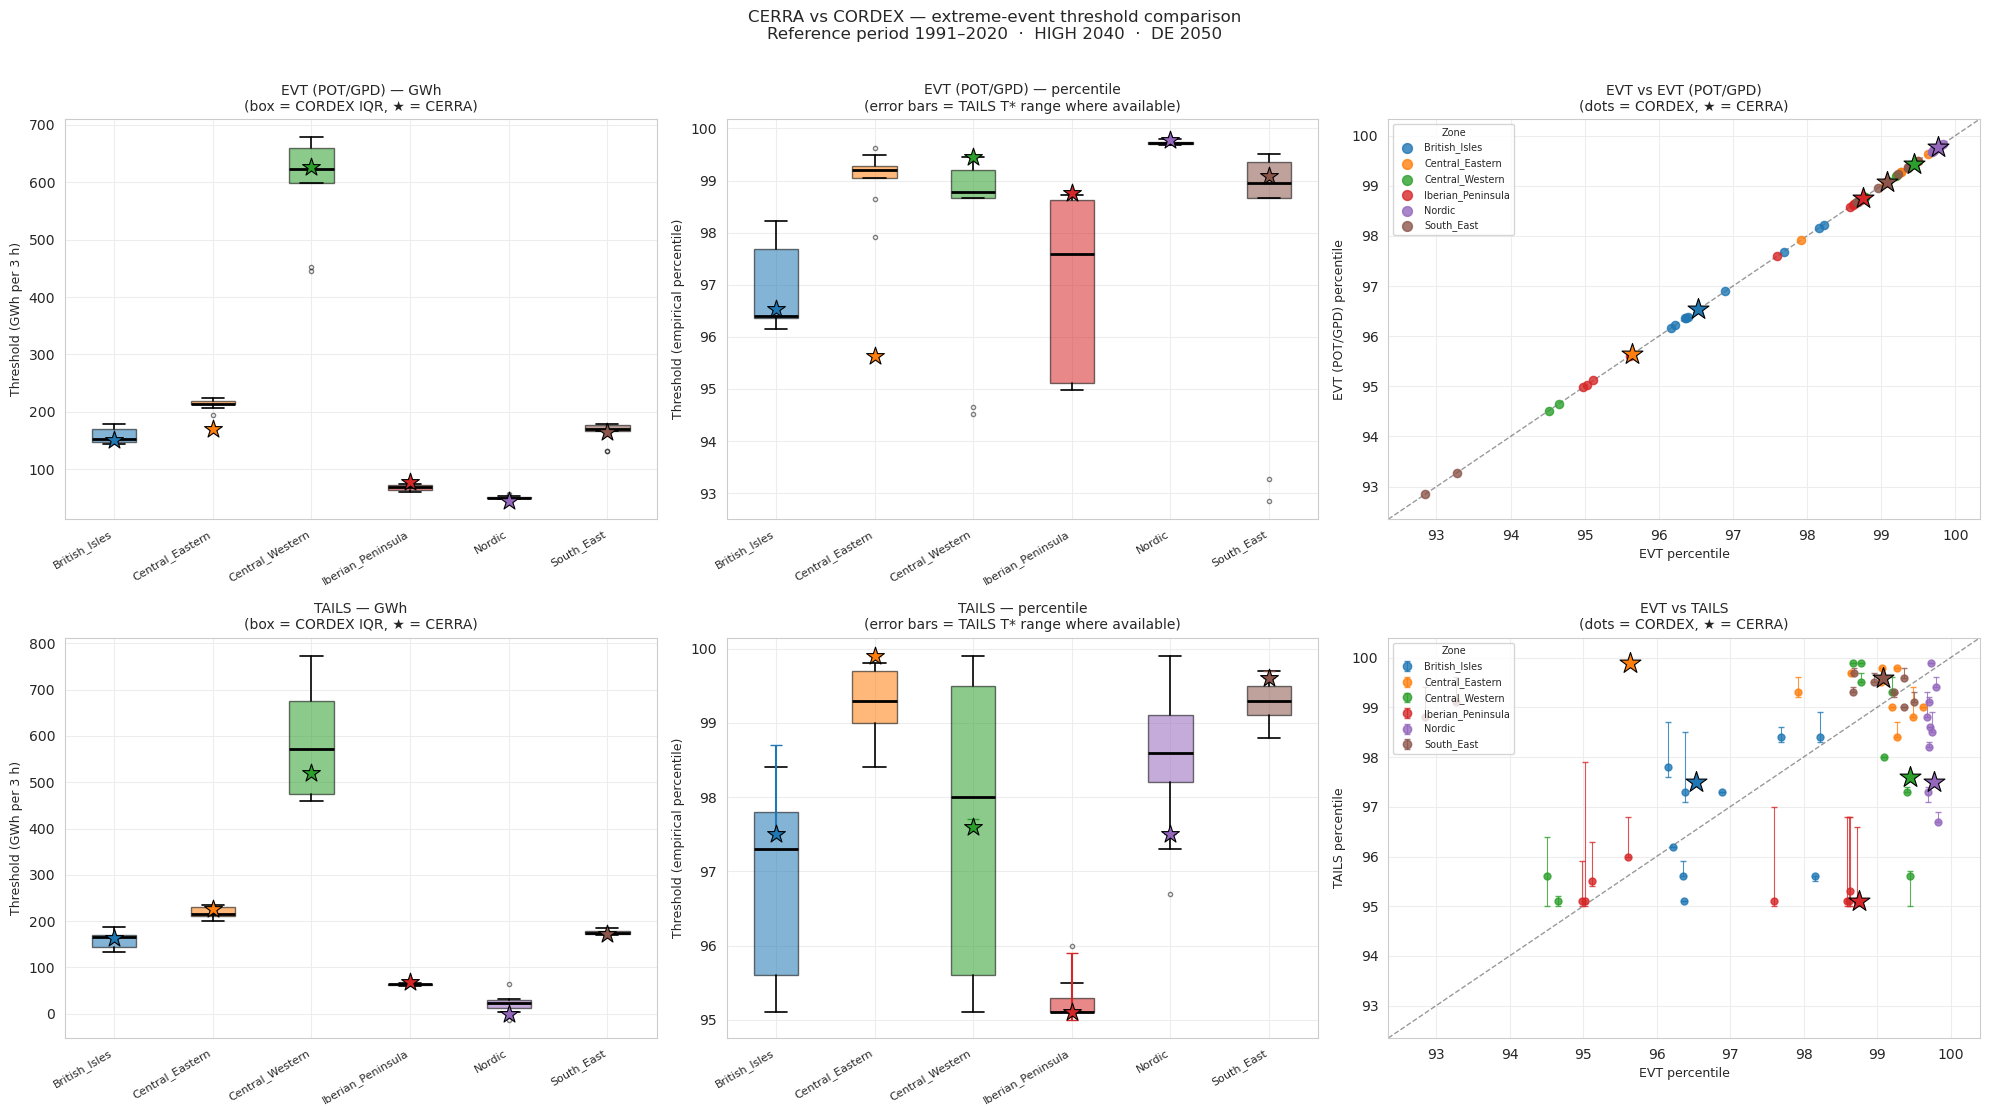

In [18]:
zone_palette = dict(zip([str(z) for z in zones], sns.color_palette("tab10", len(zones))))

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle(
    f"CERRA vs CORDEX — extreme-event threshold comparison\n"
    f"Reference period {REFERENCE_PERIOD[0]}–{REFERENCE_PERIOD[1]}  ·  {supply_scenario} {supply_year}  ·  {demand_scenario} {demand_year}",
    fontsize=12, y=1.01,
)

for row_idx, (method, gwh_col, pct_col, lo_col, hi_col) in enumerate([
    ("EVT (POT/GPD)",  "EVT_gwh",   "EVT_pct",   None,          None),
    ("TAILS",          "TAILS_gwh", "TAILS_pct", "TAILS_lo_pct", "TAILS_hi_pct"),
]):
    ax_gwh, ax_pct, ax_scatter = axes[row_idx]

    zone_list = [str(z) for z in zones]
    _offsets  = np.arange(len(zone_list))

    # ── Left: GWh box plot with CERRA star ────────────────────────────────────
    box_data = [df_cordex[df_cordex["zone"] == z][gwh_col].values for z in zone_list]
    bp = ax_gwh.boxplot(
        box_data, positions=_offsets, widths=0.45, patch_artist=True,
        medianprops=dict(color="k", lw=2),
        whiskerprops=dict(lw=1.2), capprops=dict(lw=1.2),
        flierprops=dict(marker="o", markersize=3, alpha=0.5),
        zorder=2,
    )
    for patch, z in zip(bp["boxes"], zone_list):
        patch.set_facecolor(zone_palette[z])
        patch.set_alpha(0.55)
    for i, z in enumerate(zone_list):
        cerra_val = float(df_cerra[df_cerra["zone"] == z][gwh_col].values[0])
        ax_gwh.scatter(i, cerra_val, marker="*", s=180, color=zone_palette[z],
                       edgecolors="k", linewidths=0.8, zorder=5)
    ax_gwh.set_xticks(_offsets)
    ax_gwh.set_xticklabels(zone_list, rotation=30, ha="right", fontsize=8)
    ax_gwh.set_ylabel("Threshold (GWh per 3 h)", fontsize=9)
    ax_gwh.set_title(f"{method} — GWh\n(box = CORDEX IQR, ★ = CERRA)", fontsize=10)

    # ── Centre: percentile box plot with CERRA star ───────────────────────────
    box_pct = [df_cordex[df_cordex["zone"] == z][pct_col].values for z in zone_list]
    bp2 = ax_pct.boxplot(
        box_pct, positions=_offsets, widths=0.45, patch_artist=True,
        medianprops=dict(color="k", lw=2),
        whiskerprops=dict(lw=1.2), capprops=dict(lw=1.2),
        flierprops=dict(marker="o", markersize=3, alpha=0.5),
        zorder=2,
    )
    for patch, z in zip(bp2["boxes"], zone_list):
        patch.set_facecolor(zone_palette[z])
        patch.set_alpha(0.55)
    for i, z in enumerate(zone_list):
        row_c = df_cerra[df_cerra["zone"] == z].iloc[0]
        cerra_pct = row_c[pct_col]
        ax_pct.scatter(i, cerra_pct, marker="*", s=180, color=zone_palette[z],
                       edgecolors="k", linewidths=0.8, zorder=5)
        if lo_col and not np.isnan(row_c[lo_col]):
            ax_pct.errorbar(
                i, cerra_pct,
                yerr=[[max(0.0, cerra_pct - row_c[lo_col])],
                      [max(0.0, row_c[hi_col] - cerra_pct)]],
                fmt="none", color=zone_palette[z], elinewidth=1.5, capsize=4, zorder=4,
            )
    ax_pct.set_xticks(_offsets)
    ax_pct.set_xticklabels(zone_list, rotation=30, ha="right", fontsize=8)
    ax_pct.set_ylabel("Threshold (empirical percentile)", fontsize=9)
    ax_pct.set_title(f"{method} — percentile\n(error bars = TAILS T* range where available)", fontsize=10)

    # ── Right: EVT pct vs TAILS pct scatter ──────────────────────────────────
    for z in zone_list:
        sub = df_cordex[df_cordex["zone"] == z]
        if lo_col:
            yerr = np.array([
                np.clip(sub[pct_col].values - sub[lo_col].values, 0, None),
                np.clip(sub[hi_col].values  - sub[pct_col].values, 0, None),
            ])
            ax_scatter.errorbar(
                sub["EVT_pct"], sub[pct_col],
                yerr=np.nan_to_num(yerr, nan=0.0),
                fmt="o", color=zone_palette[z], label=z,
                markersize=5, alpha=0.8, elinewidth=0.8, capsize=2, zorder=3,
            )
        else:
            ax_scatter.scatter(sub["EVT_pct"], sub[pct_col],
                               color=zone_palette[z], s=35, alpha=0.8, label=z, zorder=3)
        # CERRA star
        cerra_row = df_cerra[df_cerra["zone"] == z].iloc[0]
        ax_scatter.scatter(
            cerra_row["EVT_pct"], cerra_row[pct_col],
            marker="*", s=250, color=zone_palette[z], edgecolors="k", linewidths=0.8, zorder=6,
        )
    _lo = df_cmp[["EVT_pct", pct_col]].min().min() - 0.5
    _hi = df_cmp[["EVT_pct", pct_col]].max().max() + 0.5
    ax_scatter.plot([_lo, _hi], [_lo, _hi], "k--", lw=1, alpha=0.4)
    ax_scatter.set_xlim(_lo, _hi)
    ax_scatter.set_ylim(_lo, _hi)
    ax_scatter.set_xlabel("EVT percentile", fontsize=9)
    ax_scatter.set_ylabel(f"{method} percentile", fontsize=9)
    ax_scatter.set_title(f"EVT vs {method}\n(dots = CORDEX, ★ = CERRA)", fontsize=10)
    ax_scatter.legend(title="Zone", fontsize=7, title_fontsize=7, loc="upper left",
                      markerscale=1.2, framealpha=0.8)

plt.tight_layout()
plt.show()

In [19]:
# ── Numeric summary: CERRA vs CORDEX ensemble median/IQR per zone ─────────────
summary_rows = []
for z in [str(z) for z in zones]:
    cordex_z = df_cordex[df_cordex["zone"] == z]
    cerra_z  = df_cerra[df_cerra["zone"] == z].iloc[0]
    for method, gwh_col, pct_col in [
        ("EVT",   "EVT_gwh",   "EVT_pct"),
        ("TAILS", "TAILS_gwh", "TAILS_pct"),
    ]:
        q25, med, q75 = cordex_z[gwh_col].quantile([0.25, 0.5, 0.75]).values
        q25p, medp, q75p = cordex_z[pct_col].quantile([0.25, 0.5, 0.75]).values
        summary_rows.append({
            "Zone":              z,
            "Method":            method,
            "CERRA_GWh":         round(cerra_z[gwh_col], 1),
            "CORDEX_med_GWh":    round(med, 1),
            "CORDEX_IQR_GWh":    f"[{q25:.1f}, {q75:.1f}]",
            "CERRA_pct":         round(cerra_z[pct_col], 1),
            "CORDEX_med_pct":    round(medp, 1),
            "CORDEX_IQR_pct":    f"[{q25p:.1f}, {q75p:.1f}]",
            "bias_pct_pts":      round(medp - cerra_z[pct_col], 1),
        })

df_summary = pd.DataFrame(summary_rows)
df_summary.set_index(["Zone", "Method"], inplace=True)
print("CERRA vs CORDEX ensemble — threshold summary (reference period)")
print("bias_pct_pts = CORDEX ensemble median − CERRA (positive → CORDEX threshold stricter)\n")
df_summary

CERRA vs CORDEX ensemble — threshold summary (reference period)
bias_pct_pts = CORDEX ensemble median − CERRA (positive → CORDEX threshold stricter)



CERRA_GWh  CORDEX_med_GWh  CORDEX_IQR_GWh  \
Zone              Method                                              
British_Isles     EVT         151.4           152.8  [148.0, 170.6]   
                  TAILS       163.3           164.7  [143.3, 169.9]   
Central_Eastern   EVT         170.1           214.2  [213.9, 218.9]   
                  TAILS       227.1           215.3  [210.3, 229.6]   
Central_Western   EVT         626.7           623.0  [598.0, 659.7]   
                  TAILS       520.5           571.2  [474.8, 675.4]   
Iberian_Peninsula EVT          77.0            69.2    [64.3, 72.7]   
                  TAILS        67.6            64.0    [62.6, 64.8]   
Nordic            EVT          44.7            50.2    [49.9, 52.1]   
                  TAILS         0.2            24.1    [13.0, 28.8]   
South_East        EVT         165.4           170.7  [166.9, 177.3]   
                  TAILS       172.1           173.4  [171.3, 178.5]   

                          CERRA_pct  CORDEX_med_pct CORDEX_IQR_pct  \
Zone              Method                                             
British_Isles     EVT          96.5            96.4   [96.4, 97.7]   
                  TAILS        97.5            97.3   [95.6, 97.8]   
Central_Eastern   EVT          95.6            99.2   [99.1, 99.3]   
                  TAILS        99.9            99.3   [99.0, 99.7]   
Central_Western   EVT          99.4            98.8   [98.7, 99.2]   
                  TAILS        97.6            98.0   [95.6, 99.5]   
Iberian_Peninsula EVT          98.8            97.6   [95.1, 98.6]   
                  TAILS        95.1            95.1   [95.1, 95.3]   
Nordic            EVT          99.8            99.7   [99.7, 99.7]   
                  TAILS        97.5            98.6   [98.2, 99.1]   
South_East        EVT          99.1            99.0   [98.7, 99.4]   
                  TAILS        99.6            99.3   [99.1, 99.5]   

                          bias_pct_pts  
Zone              Method                
British_Isles     EVT             -0.1  
                  TAILS           -0.2  
Central_Eastern   EVT              3.6  
                  TAILS           -0.6  
Central_Western   EVT             -0.7  
                  TAILS            0.4  
Iberian_Peninsula EVT             -1.2  
                  TAILS           -0.0  
Nordic            EVT             -0.1  
                  TAILS            1.1  
South_East        EVT             -0.1  
                  TAILS           -0.3

In [21]:
df_cerra

,source,model,zone,EVT_gwh,EVT_pct,TAILS_gwh,TAILS_pct,TAILS_lo_pct,TAILS_hi_pct
54,CERRA,CERRA,British_Isles,151.428527,96.534247,163.252080,97.500000,97.5,98.7
55,CERRA,CERRA,Central_Eastern,170.143066,95.635845,227.104856,99.899543,99.9,99.9
56,CERRA,CERRA,Central_Western,626.747687,99.441781,520.519535,97.599315,97.6,97.7
57,CERRA,CERRA,Iberian_Peninsula,76.985545,98.759132,67.567432,95.099315,95.0,95.9
58,CERRA,CERRA,Nordic,44.661121,99.770548,0.196454,97.500000,97.5,97.5
59,CERRA,CERRA,South_East,165.369422,99.082192,172.088604,99.599315,99.6,99.7


## EVT vs TAILS method comparison

Scatter and heatmap comparing the two threshold selection methods across all
CORDEX models and zones, with the CERRA value overlaid as a star.  The
percentile representation is the common currency: both methods operate on
different scales (GWh / Z-score) but share the same empirical rank space.

A positive difference (TAILS − EVT) means TAILS selects a stricter threshold;
negative means EVT is more conservative.  The TAILS 95 % floor prevents
sub-95th-percentile selections that EVT can produce in low-variability zones.

In [ ]:
# ── EVT vs TAILS comparison (CORDEX ensemble + CERRA overlay) ─────────────────

def _model_short_label(m: str) -> str:
    parts = m.split("_")
    rcm = parts[0].split("-", 1)[1]
    gcm = "-".join(parts[1].split("-")[-2:])
    return f"{rcm}/{gcm}"

# Build flat comparison table from CORDEX rows of df_cmp
df_cmp_methods = df_cordex.copy()
df_cmp_methods["diff_pct"]    = df_cmp_methods["TAILS_pct"] - df_cmp_methods["EVT_pct"]
df_cmp_methods["model_short"] = df_cmp_methods["model"].map(_model_short_label)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    f"EVT vs TAILS threshold selection — CORDEX ensemble (★ = CERRA)\n"
    f"Reference period {REFERENCE_PERIOD[0]}–{REFERENCE_PERIOD[1]}  ·  {supply_scenario} {supply_year}",
    fontsize=11, y=1.02,
)

zone_list = [str(z) for z in zones]
zone_pal  = dict(zip(zone_list, sns.color_palette("tab10", len(zone_list))))

# ── Left: scatter EVT pct vs TAILS pct, error bars = T* range ────────────────
ax = axes[0]
for z in zone_list:
    sub = df_cmp_methods[df_cmp_methods["zone"] == z]
    yerr = np.array([
        np.clip(sub["TAILS_pct"].values - sub["TAILS_lo_pct"].values, 0, None),
        np.clip(sub["TAILS_hi_pct"].values - sub["TAILS_pct"].values, 0, None),
    ])
    ax.errorbar(
        sub["EVT_pct"], sub["TAILS_pct"],
        yerr=np.nan_to_num(yerr, nan=0.0),
        fmt="o", color=zone_pal[z], label=z,
        markersize=5, alpha=0.85, elinewidth=1, capsize=3, zorder=3,
    )
    # CERRA star
    row_c = df_cerra[df_cerra["zone"] == z].iloc[0]
    c_err = np.array([
        [max(0.0, row_c["TAILS_pct"] - (row_c["TAILS_lo_pct"] if not np.isnan(row_c["TAILS_lo_pct"]) else row_c["TAILS_pct"]))],
        [max(0.0, (row_c["TAILS_hi_pct"] if not np.isnan(row_c["TAILS_hi_pct"]) else row_c["TAILS_pct"]) - row_c["TAILS_pct"])],
    ])
    ax.errorbar(
        row_c["EVT_pct"], row_c["TAILS_pct"],
        yerr=c_err,
        fmt="*", color=zone_pal[z], markersize=14, markeredgecolor="k",
        markeredgewidth=0.8, elinewidth=1.5, capsize=4, zorder=6,
    )

_lo = df_cmp[["EVT_pct", "TAILS_pct"]].min().min() - 0.5
_hi = df_cmp[["EVT_pct", "TAILS_pct"]].max().max() + 0.5
ax.plot([_lo, _hi], [_lo, _hi], "k--", lw=1, alpha=0.5, label="1:1 line")
ax.set_xlim(_lo, _hi)
ax.set_ylim(_lo, _hi)
ax.set_xlabel("EVT/POT threshold (percentile)", fontsize=10)
ax.set_ylabel("TAILS threshold (percentile)", fontsize=10)
ax.set_title(
    "EVT vs TAILS — percentile agreement\n(error bars = TAILS T* indistinguishable range, ★ = CERRA)",
    fontsize=10,
)
ax.legend(title="Zone", fontsize=8, title_fontsize=8, loc="upper left")

# ── Right: difference heatmap TAILS − EVT (percentile points) ─────────────────
ax = axes[1]
pivot = df_cmp_methods.pivot(index="zone", columns="model_short", values="diff_pct")
_vmax = max(np.abs(pivot.values[np.isfinite(pivot.values)]).max(), 0.5)
sns.heatmap(
    pivot, ax=ax,
    cmap="RdBu_r", center=0, vmin=-_vmax, vmax=_vmax,
    annot=True, fmt="+.1f", linewidths=0.4,
    cbar_kws={"label": "TAILS − EVT (pct-points)"},
)
ax.set_title(
    "TAILS − EVT (percentile points)\npositive = TAILS picks a stricter threshold",
    fontsize=10,
)
ax.set_xlabel("Model (RCM / GCM)", fontsize=9)
ax.set_ylabel("Zone", fontsize=9)
ax.tick_params(axis="x", rotation=45, labelsize=7)
ax.tick_params(axis="y", rotation=0, labelsize=8)

plt.tight_layout()
plt.show()

# ── Summary statistics ────────────────────────────────────────────────────────
print("TAILS − EVT difference (percentile points) by zone:")
print(
    df_cmp_methods.groupby("zone")[["EVT_pct", "TAILS_pct", "TAILS_lo_pct", "TAILS_hi_pct", "diff_pct"]]
    .mean()
    .round(2)
    .to_string()
)
r = df_cmp_methods[["EVT_pct", "TAILS_pct"]].corr().iloc[0, 1]
print(f"\nPearson r(EVT pct, TAILS pct) across all CORDEX model × zone: {r:.3f}")

## TAILS NaN-range diagnostic

When the T* indistinguishable range is NaN, `find_tails_threshold` fell back to
the 0.99 quantile because no candidate threshold jointly satisfied all three
eq. 7 filters (GPD convergence, AD goodness-of-fit, minimum event count).
This cell identifies and diagnoses those cases for the CORDEX ensemble.

In [ ]:
# ── TAILS NaN-range diagnostic for CORDEX ─────────────────────────────────────
from cordex2energy_analysis.extremes_thresholds import find_tails_threshold

nan_cases = (
    df_cmp_methods[df_cmp_methods["TAILS_lo_pct"].isna() | df_cmp_methods["TAILS_hi_pct"].isna()]
    [["model", "zone"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

if nan_cases.empty:
    print("✓  No NaN range cases — every CORDEX model × zone pair passed the eq. 7 filter.")
else:
    print(
        f"  {len(nan_cases)} model × zone pair(s) triggered the TAILS fallback "
        f"(T* range = NaN).\n"
    )
    print(
        f"  {'Model':<55}  {'Zone':<22}  {'cands':>5}  "
        f"{'fit_ok':>6}  {'pass_AD':>7}  {'pass_evt':>8}  {'pass_all':>8}  "
        f"{'knee_q':>6}  {'q_lower':>7}  {'EVT_pct':>7}  {'TAILS_pct':>9}"
    )
    print("  " + "-" * 140)

    for _, row in nan_cases.iterrows():
        model = row["model"]
        zone  = row["zone"]

        da_zone     = rl_ref_cordex[model].sel(zone=zone)
        zone_series = da_zone.values.flatten()
        zone_years  = da_zone["time"].dt.year.values

        result = find_tails_threshold(
            zone_series,
            years=zone_years,
            threshold_type="yearly",
            random_seed=0,
        )
        d = result.diagnostics

        evt_pct_val   = float(df_cmp_methods.loc[(df_cmp_methods["model"] == model) & (df_cmp_methods["zone"] == zone), "EVT_pct"].iloc[0])
        tails_pct_val = float(df_cmp_methods.loc[(df_cmp_methods["model"] == model) & (df_cmp_methods["zone"] == zone), "TAILS_pct"].iloc[0])

        print(
            f"  {model:<55}  {zone:<22}  "
            f"{d['n_candidates']:>5}  "
            f"{d['n_fit_ok']:>6}  "
            f"{d['n_pass_ad']:>7}  "
            f"{d['n_pass_events']:>8}  "
            f"{d['n_pass_all']:>8}  "
            f"{result.knee_quantile:>6.3f}  "
            f"{result.q_lower:>7.3f}  "
            f"{evt_pct_val:>7.1f}  "
            f"{tails_pct_val:>9.1f}"
        )

    print(
        "\n  Columns: cands = candidate thresholds scanned | fit_ok = GPD fit converged (n_exc ≥ 30)\n"
        "           pass_AD = fit_ok AND right-tail AD p > 0.05 | pass_evt = n_events ≥ 1/yr × n_years\n"
        "           pass_all = all three conditions | knee_q / q_lower = knee / lower bound of candidate grid"
    )

    # ── Visual: filter traces for the first NaN case ──────────────────────────
    _ex     = nan_cases.iloc[0]
    _da     = rl_ref_cordex[_ex["model"]].sel(zone=_ex["zone"])
    _result = find_tails_threshold(
        _da.values.flatten(),
        years=_da["time"].dt.year.values,
        threshold_type="yearly",
        random_seed=0,
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    ax = axes[0]
    ax.plot(_result.candidates_quantile * 100, _result.ad_pvalues, lw=1.5, color="#E24A4A")
    ax.axhline(0.05, color="k", lw=1, ls="--", label="p = 0.05 cutoff")
    ax.set_xlabel("Candidate threshold (percentile)")
    ax.set_ylabel("Right-tail AD p-value")
    ax.set_title("AD p-value across candidate grid")
    ax.legend(fontsize=8)

    ax = axes[1]
    ax.plot(_result.candidates_quantile * 100, _result.n_events, lw=1.5, color="#4A90E2")
    ax.axhline(
        _result.diagnostics["min_events_applied"], color="k", lw=1, ls="--",
        label=f"min = {_result.diagnostics['min_events_applied']} events",
    )
    ax.set_xlabel("Candidate threshold (percentile)")
    ax.set_ylabel("Declustered event count")
    ax.set_title("Event count across candidate grid")
    ax.legend(fontsize=8)

    ax = axes[2]
    _fm = np.isfinite(_result.distances)
    if _fm.any():
        ax.plot(
            _result.candidates_quantile[_fm] * 100,
            _result.distances[_fm],
            lw=1.5, color="#7570B3",
        )
    ax.set_xlabel("Candidate threshold (percentile)")
    ax.set_ylabel("Mean bootstrap QQ distance")
    ax.set_title("QQ distance (finite where GPD fit ok)")

    plt.suptitle(
        f"TAILS fallback diagnostic — {_ex['model'].split('_')[0]}  /  {_ex['zone']}\n"
        "All three filters must overlap at the same quantile to avoid fallback",
        fontsize=10, y=1.02,
    )
    plt.tight_layout()
    plt.show()